In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("\nClass distribution:\n", df["species"].value_counts())
df.head()

Shape: (150, 6)
Missing values: 0

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


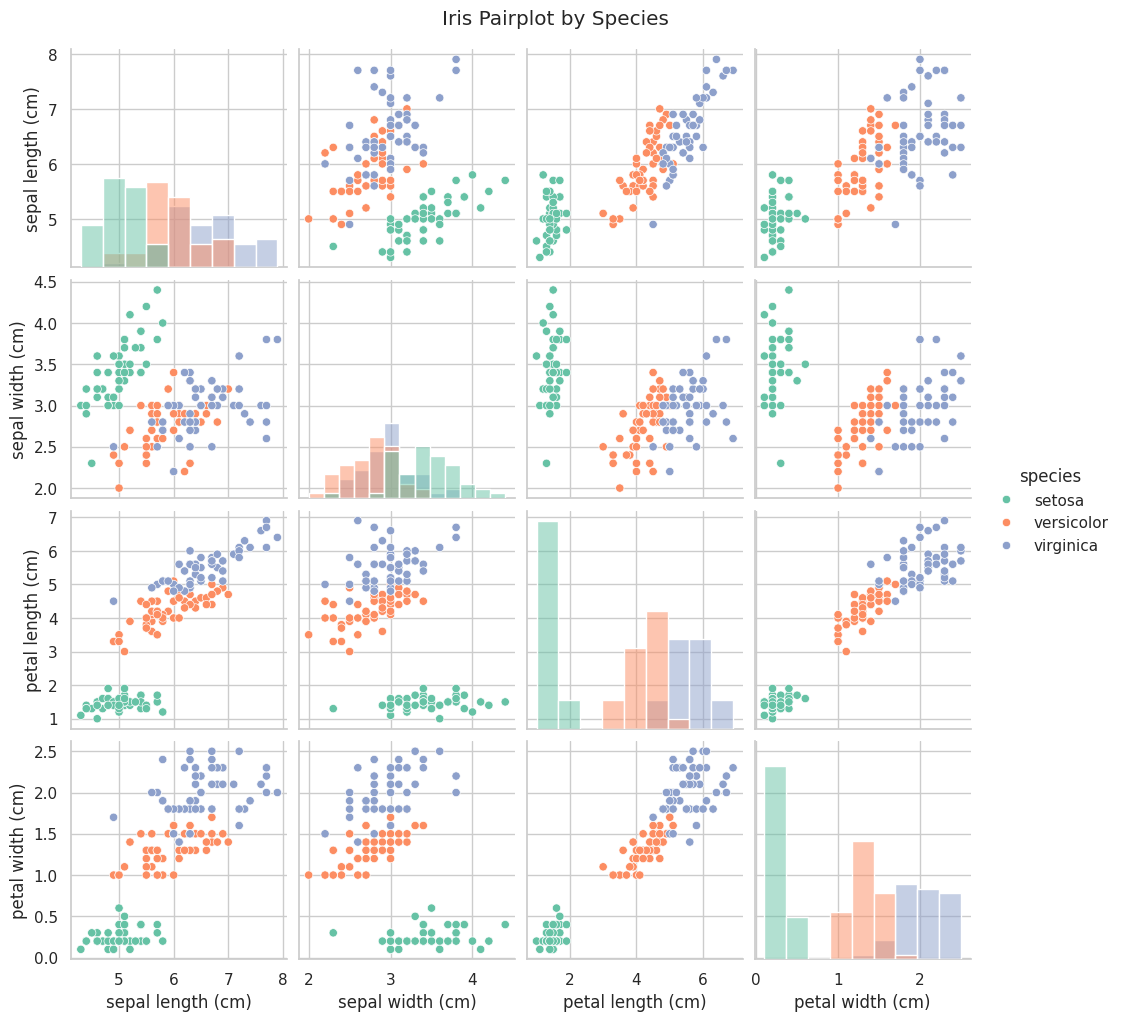

In [3]:
sns.pairplot(df.drop(columns="target"), hue="species", palette="Set2", diag_kind="hist")
plt.suptitle("Iris Pairplot by Species", y=1.02)
plt.show()

In [4]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Fit the scaler on training data only to avoid data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])
print("Scaled train mean (approx 0):", X_train_scaled.mean(axis=0).round(3))
print("Scaled train std  (approx 1):", X_train_scaled.std(axis=0).round(3))

Train size: 120 | Test size: 30
Scaled train mean (approx 0): [-0.  0.  0.  0.]
Scaled train std  (approx 1): [1. 1. 1. 1.]


In [5]:
log_reg = LogisticRegression(max_iter=200, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train_scaled, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": tree}
preds = {name: m.predict(X_test_scaled) for name, m in models.items()}
print("Models trained.")

Models trained.


In [6]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

for name, y_pred in preds.items():
    print("=" * 60)
    print(name, "- Classification Report")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=iris.target_names))

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


Logistic Regression - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



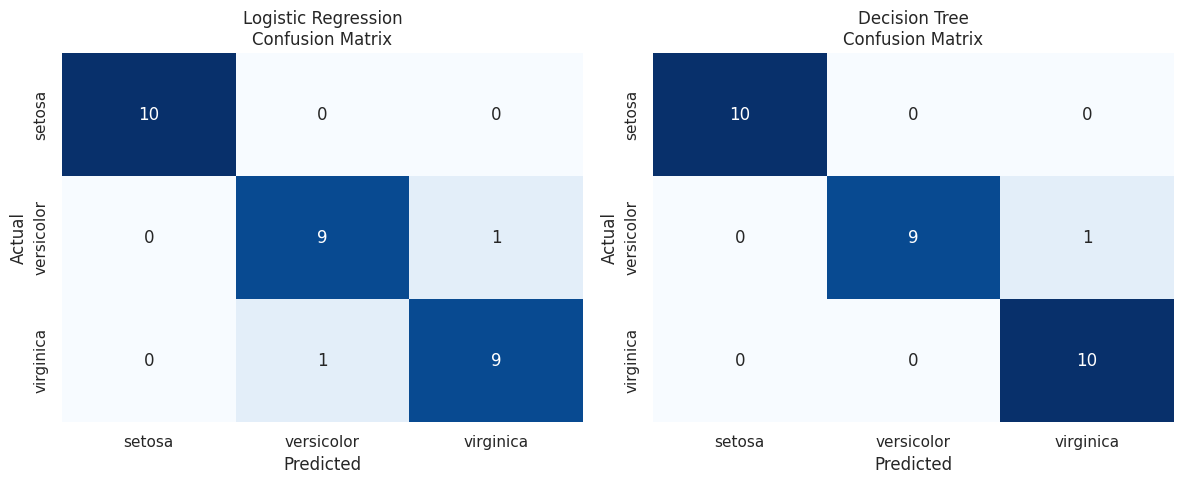

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

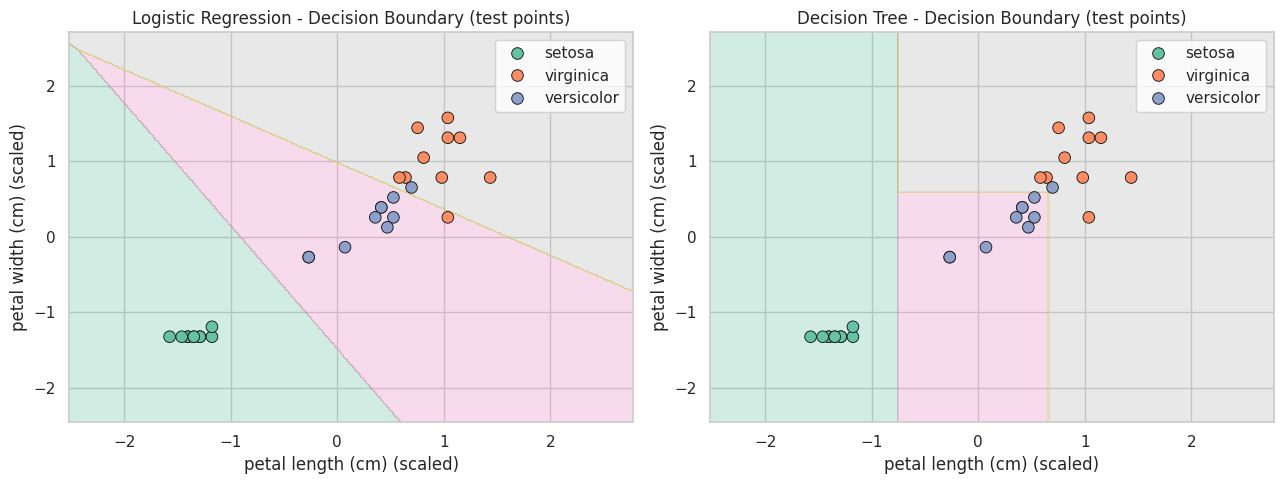

In [8]:
feat_idx = [2, 3]  # petal length, petal width
feat_names = [iris.feature_names[i] for i in feat_idx]

X2_train = X_train_scaled[:, feat_idx]
X2_test = X_test_scaled[:, feat_idx]

vis_models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=RANDOM_STATE).fit(X2_train, y_train),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X2_train, y_train),
}

x_min, x_max = X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1
y_min, y_max = X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, vis_models.items()):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="Set2")
    sns.scatterplot(x=X2_test[:, 0], y=X2_test[:, 1],
                    hue=[iris.target_names[i] for i in y_test],
                    palette="Set2", edgecolor="k", s=70, ax=ax)
    ax.set_title(f"{name} - Decision Boundary (test points)")
    ax.set_xlabel(feat_names[0] + " (scaled)")
    ax.set_ylabel(feat_names[1] + " (scaled)")
plt.tight_layout()
plt.show()

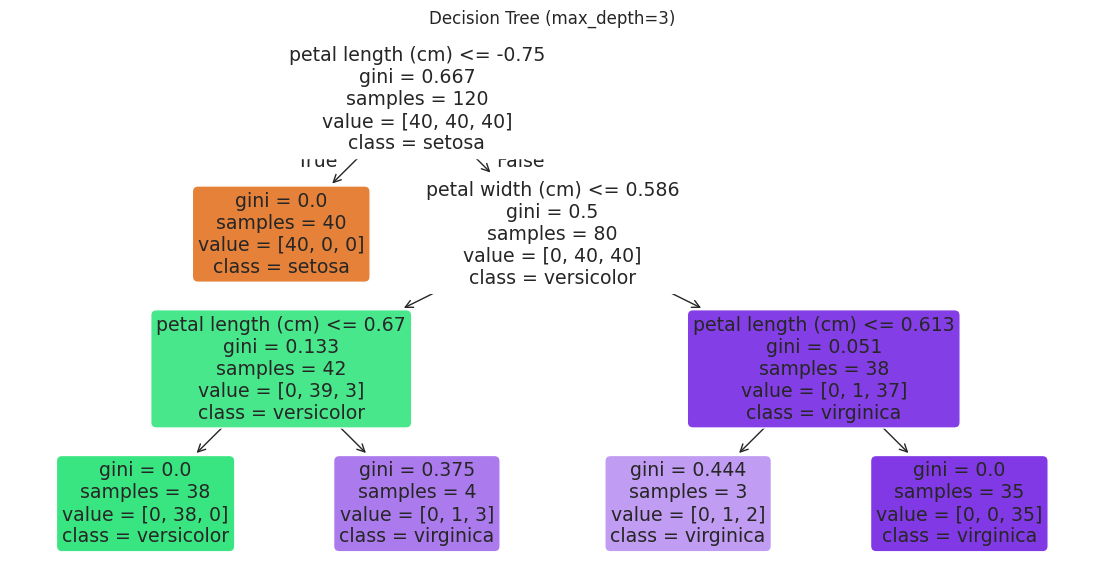

In [9]:
plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=iris.feature_names, class_names=list(iris.target_names),
          filled=True, rounded=True)
plt.title("Decision Tree (max_depth=3)")
plt.show()